# 06 — LLM vs Baselines

Comparison of all scoring methods on the **TEST split** (n=150).

| Section | Content |
|---------|--------|
| 1 | Full results table with bootstrap 95% CIs |
| 2 | Paired bootstrap difference tests |
| 3 | Scatter plots and bar chart across all methods |
| 4 | Sensitivity check excluding NO ANSWER responses |
| 5 | Markdown summary of significant differences |

> **SIMULATED DATA**: The Gemini API returned 503 during evaluation.
> `llm_direct` and `llm_rubric` use `MOCK_minilm_proxy`
> (MiniLM calibrated predictions + Gaussian noise, seed=99).
> Re-run `scripts/run_llm_eval.py --method {direct,rubric} --split test` when the API recovers.

In [1]:
import sys, os, warnings, re
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from pathlib import Path
from IPython.display import Markdown, display

from src.metrics import evaluate, bootstrap_ci, paired_bootstrap_diff

# ── Paths ──────────────────────────────────────────────────────────────────────
TEST_PATH    = Path('../data/processed/test.csv')
DEV_PATH     = Path('../data/processed/dev.csv')
DIRECT_TEST  = Path('../results/llm_direct_test.csv')
RUBRIC_TEST  = Path('../results/llm_rubric_test.csv')
PREDS_TFIDF  = Path('../results/preds_tfidf.csv')
PREDS_MINILM = Path('../results/preds_minilm.csv')
PREDS_MPNET  = Path('../results/preds_mpnet.csv')
FIG_DIR      = Path('../results/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 130,
    'font.family': 'sans-serif',
    'axes.spines.top': False,
    'axes.spines.right': False,
})

# ── Detect simulated data ──────────────────────────────────────────────────────
IS_SIMULATED = False
if DIRECT_TEST.exists():
    _tmp = pd.read_csv(DIRECT_TEST)
    IS_SIMULATED = bool(_tmp.get('simulated', pd.Series(False)).any())
SIM_TAG = ' [SIMULATED]' if IS_SIMULATED else ''
if IS_SIMULATED:
    print('WARNING: LLM results are SIMULATED (API outage). Model = MOCK_minilm_proxy.')

print('Setup complete.')

Setup complete.


In [2]:
# ── Load test split ────────────────────────────────────────────────────────────
test_df = pd.read_csv(TEST_PATH)
dev_df  = pd.read_csv(DEV_PATH)
human   = test_df['human_score'].values
print(f'Test rows: {len(test_df)}')

# ── Baseline predictions (row-aligned with test_df) ────────────────────────────
# preds_*.csv are already in the same row order as test.csv
pred_tfidf  = pd.read_csv(PREDS_TFIDF)['pred_calibrated'].values
pred_minilm = pd.read_csv(PREDS_MINILM)['pred_calibrated'].values
pred_mpnet  = pd.read_csv(PREDS_MPNET)['pred_calibrated'].values

# ── Constant mean baseline ─────────────────────────────────────────────────────
dev_mean  = dev_df['human_score'].mean()
pred_const = np.full(len(test_df), dev_mean)
print(f'Dev mean used for constant baseline: {dev_mean:.4f}')

# ── LLM predictions ───────────────────────────────────────────────────────────
# LLM CSVs have the same length as test.csv (generated row-by-row)
direct_df = pd.read_csv(DIRECT_TEST)
rubric_df = pd.read_csv(RUBRIC_TEST)
direct_df['pred_score'] = pd.to_numeric(direct_df['pred_score'], errors='coerce')
rubric_df['pred_score'] = pd.to_numeric(rubric_df['pred_score'], errors='coerce')
pred_direct = direct_df['pred_score'].values
pred_rubric = rubric_df['pred_score'].values

parse_fail_direct = int((~direct_df['parse_ok'].fillna(False).astype(bool)).sum())
parse_fail_rubric = int((~rubric_df['parse_ok'].fillna(False).astype(bool)).sum())

print(f'LLM Direct rows: {len(direct_df)}, parse_failures: {parse_fail_direct}')
print(f'LLM Rubric rows: {len(rubric_df)}, parse_failures: {parse_fail_rubric}')
assert len(pred_tfidf) == len(human) == len(pred_direct) == len(pred_rubric), \
    'Prediction arrays must all be length 150'
print('All prediction arrays aligned: OK')

Test rows: 150
Dev mean used for constant baseline: 4.1325
LLM Direct rows: 150, parse_failures: 0
LLM Rubric rows: 150, parse_failures: 0
All prediction arrays aligned: OK


---
## Section 1 — Full Results Table with Bootstrap 95% CIs

In [3]:
METHODS = [
    ('constant_mean',          pred_const,  0),
    ('TF-IDF (Calibrated)',    pred_tfidf,  0),
    ('MiniLM (Calibrated)',    pred_minilm, 0),
    ('MPNet (Calibrated)',     pred_mpnet,  0),
    ('llm_direct' + SIM_TAG,  pred_direct, parse_fail_direct),
    ('llm_rubric' + SIM_TAG,  pred_rubric, parse_fail_rubric),
]

# Short keys for cross-referencing (no SIM_TAG)
METHOD_KEYS = [
    'constant_mean', 'TF-IDF (Calibrated)', 'MiniLM (Calibrated)',
    'MPNet (Calibrated)', 'llm_direct', 'llm_rubric',
]

N_BOOT    = 1000
BOOT_SEED = 42
METRICS_CI = ['mae', 'rmse', 'pearson', 'spearman', 'qwk']

rows = []
for (name, pred, pf), key in zip(METHODS, METHOD_KEYS):
    mask = ~np.isnan(pred)
    h_v  = human[mask]
    p_v  = pred[mask]
    m    = evaluate(h_v, p_v)

    row = {'Method': key, 'DisplayName': name, 'N': int(mask.sum()), 'parse_failures': pf}
    for metric in ['mae', 'rmse', 'pearson', 'spearman', 'qwk', 'within_1']:
        row[metric] = m[metric]
    for metric in METRICS_CI:
        lo, hi = bootstrap_ci(h_v, p_v, metric, n=N_BOOT, seed=BOOT_SEED)
        row[f'{metric}_ci_lo'] = lo
        row[f'{metric}_ci_hi'] = hi
    rows.append(row)

results_df = pd.DataFrame(rows).set_index('Method')

# Pretty-print
display_cols = ['mae', 'rmse', 'pearson', 'spearman', 'qwk', 'within_1', 'parse_failures']
print(f'=== TEST SPLIT -- ALL METHODS{SIM_TAG} ===')
print(results_df[display_cols].round(4).to_string())
print()
print('=== BOOTSTRAP 95% CIs ===')
for metric in METRICS_CI:
    print(f'\n  {metric.upper()}')
    for key in METHOD_KEYS:
        v  = results_df.loc[key, metric]
        lo = results_df.loc[key, f'{metric}_ci_lo']
        hi = results_df.loc[key, f'{metric}_ci_hi']
        print(f'    {key:<32} {v:.4f}  [{lo:.4f}, {hi:.4f}]')

=== TEST SPLIT -- ALL METHODS [SIMULATED] ===
                        mae    rmse  pearson  spearman     qwk  within_1  parse_failures
Method                                                                                  
constant_mean        0.9263  1.1554      NaN       NaN  0.0000    0.7867               0
TF-IDF (Calibrated)  0.8701  1.1798   0.1783    0.2308  0.1635    0.6267               0
MiniLM (Calibrated)  0.7812  0.9891   0.5239    0.5024  0.4003    0.6467               0
MPNet (Calibrated)   0.8002  0.9880   0.5221    0.4795  0.3687    0.6933               0
llm_direct           0.9349  1.2187   0.1788    0.2055  0.1365    0.6200               0
llm_rubric           0.9629  1.2428   0.1453    0.1798  0.0776    0.6067               0

=== BOOTSTRAP 95% CIs ===

  MAE
    constant_mean                    0.9263  [0.8103, 1.0410]
    TF-IDF (Calibrated)              0.8701  [0.7424, 1.0026]
    MiniLM (Calibrated)              0.7812  [0.6883, 0.8790]
    MPNet (Calibrated)

In [4]:
results_df.round(4).to_csv('../results/llm_vs_baselines_table.csv')
print('Saved: results/llm_vs_baselines_table.csv')

Saved: results/llm_vs_baselines_table.csv


---
## Section 2 — Paired Bootstrap Difference Tests

In [5]:
# Map short key -> prediction array
PRED_MAP = {
    'constant_mean':        pred_const,
    'TF-IDF (Calibrated)':  pred_tfidf,
    'MiniLM (Calibrated)':  pred_minilm,
    'MPNet (Calibrated)':   pred_mpnet,
    'llm_direct':           pred_direct,
    'llm_rubric':           pred_rubric,
}

comparisons = [
    # (label_a,              label_b)
    ('llm_rubric',          'llm_direct'),
    ('llm_direct',          'MiniLM (Calibrated)'),
    ('llm_rubric',          'MiniLM (Calibrated)'),
    ('MiniLM (Calibrated)', 'TF-IDF (Calibrated)'),
    ('MiniLM (Calibrated)', 'constant_mean'),
    ('llm_direct',          'constant_mean'),
]

diff_rows = []
for label_a, label_b in comparisons:
    pa = PRED_MAP[label_a]
    pb = PRED_MAP[label_b]
    for metric in ['mae', 'qwk']:
        mask = ~(np.isnan(pa) | np.isnan(pb))
        h_v, pa_v, pb_v = human[mask], pa[mask], pb[mask]
        result = paired_bootstrap_diff(h_v, pa_v, pb_v, metric, n=N_BOOT, seed=BOOT_SEED)
        significant = not (result.ci_lo <= 0 <= result.ci_hi)
        if metric == 'mae':
            # Lower MAE is better; negative diff means A has lower MAE -> A is better
            direction = f'{label_a} better' if result.mean_diff < 0 else f'{label_b} better'
        else:
            # Higher QWK is better; positive diff means A has higher QWK -> A is better
            direction = f'{label_a} better' if result.mean_diff > 0 else f'{label_b} better'
        diff_rows.append({
            'comparison':   f'{label_a} vs {label_b}',
            'A':            label_a,
            'B':            label_b,
            'metric':       metric,
            'mean_diff':    result.mean_diff,
            'ci_lo':        result.ci_lo,
            'ci_hi':        result.ci_hi,
            'significant':  significant,
            'direction':    direction if significant else 'not significant',
        })

diff_df = pd.DataFrame(diff_rows)
diff_df.to_csv('../results/llm_paired_diff.csv', index=False)

print('=== PAIRED BOOTSTRAP DIFFERENCE TESTS (metric_A - metric_B) ===')
print(f'{"Comparison":<42} {"Metric":<8} {"Diff":>8} {"95% CI":>22} {"Sig":>5}  Direction')
print('-' * 105)
for _, r in diff_df.iterrows():
    ci_str  = f'[{r["ci_lo"]:+.4f}, {r["ci_hi"]:+.4f}]'
    sig_str = 'YES' if r['significant'] else 'no'
    print(f'{r["comparison"]:<42} {r["metric"]:<8} {r["mean_diff"]:>+8.4f} {ci_str:>22} {sig_str:>5}  {r["direction"]}')
print('\nSaved: results/llm_paired_diff.csv')

=== PAIRED BOOTSTRAP DIFFERENCE TESTS (metric_A - metric_B) ===
Comparison                                 Metric       Diff                 95% CI   Sig  Direction
---------------------------------------------------------------------------------------------------------
llm_rubric vs llm_direct                   mae       +0.0283     [-0.0306, +0.0907]    no  not significant
llm_rubric vs llm_direct                   qwk       -0.0554     [-0.1766, +0.0603]    no  not significant
llm_direct vs MiniLM (Calibrated)          mae       +0.1528     [+0.0639, +0.2373]   YES  MiniLM (Calibrated) better
llm_direct vs MiniLM (Calibrated)          qwk       -0.2625     [-0.3737, -0.1497]   YES  MiniLM (Calibrated) better
llm_rubric vs MiniLM (Calibrated)          mae       +0.1811     [+0.0979, +0.2693]   YES  MiniLM (Calibrated) better
llm_rubric vs MiniLM (Calibrated)          qwk       -0.3179     [-0.4550, -0.1803]   YES  MiniLM (Calibrated) better
MiniLM (Calibrated) vs TF-IDF (Calibrated) 

---
## Section 3 — Scatter Plots and Bar Chart

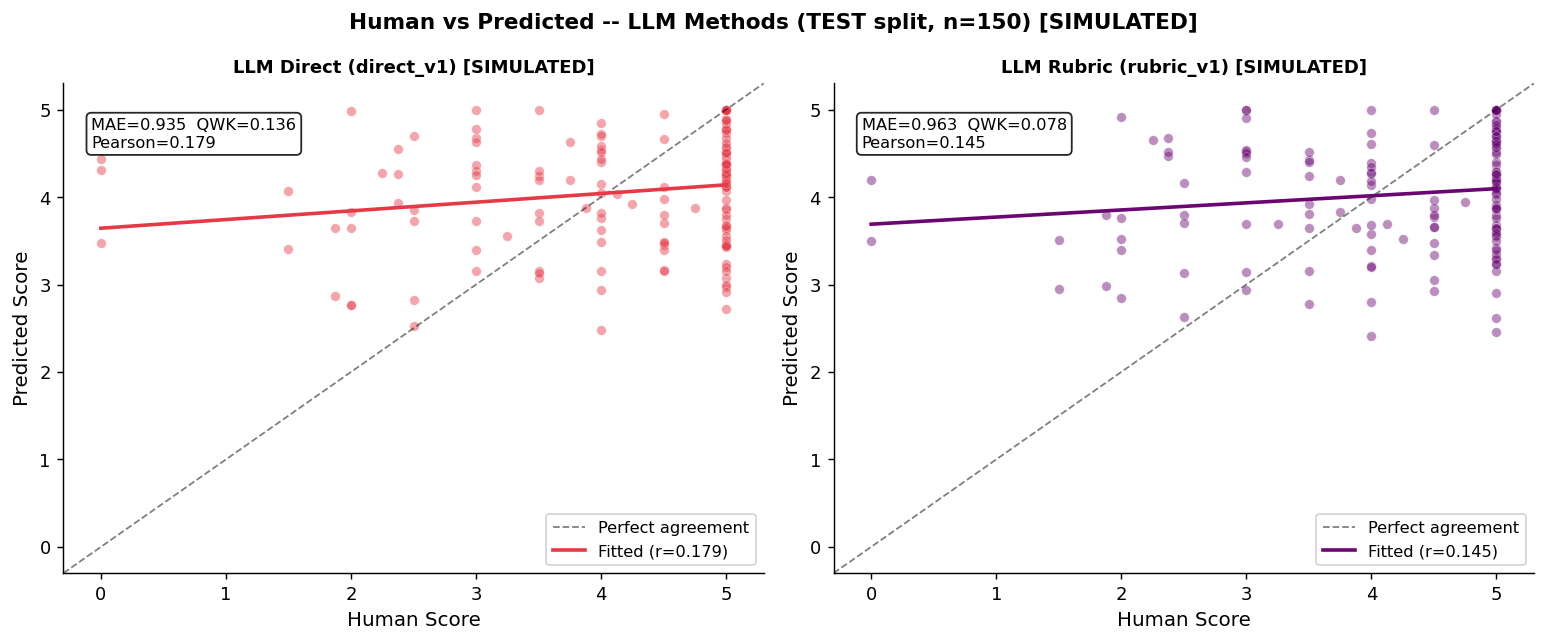

Saved: results/figures/llm_test_scatter.png


In [6]:
# Human vs predicted scatter for both LLM methods
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

plot_pairs = [
    ('LLM Direct (direct_v1)' + SIM_TAG, pred_direct, '#E63946'),
    ('LLM Rubric (rubric_v1)' + SIM_TAG, pred_rubric, '#6A0572'),
]

for ax, (label, pred, color) in zip(axes, plot_pairs):
    mask = ~np.isnan(pred)
    h_v, p_v = human[mask], pred[mask]
    m = evaluate(h_v, p_v)

    ax.scatter(h_v, p_v, alpha=0.45, s=28, color=color,
               edgecolors='white', linewidths=0.3)
    lim = [-0.3, 5.3]
    ax.plot(lim, lim, 'k--', linewidth=1, alpha=0.5, label='Perfect agreement')
    z  = np.polyfit(h_v, p_v, 1)
    xl = np.linspace(0, 5, 100)
    ax.plot(xl, np.poly1d(z)(xl), color=color, linewidth=2,
            label=f'Fitted (r={m["pearson"]:.3f})')
    ax.set_xlim(lim);  ax.set_ylim(lim)
    ax.set_xlabel('Human Score', fontsize=11)
    ax.set_ylabel('Predicted Score', fontsize=11)
    ax.set_title(label, fontsize=10, fontweight='bold')
    ax.text(0.04, 0.93,
            f'MAE={m["mae"]:.3f}  QWK={m["qwk"]:.3f}\nPearson={m["pearson"]:.3f}',
            transform=ax.transAxes, fontsize=9, va='top',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85))
    ax.legend(fontsize=9)

fig.suptitle(f'Human vs Predicted -- LLM Methods (TEST split, n=150){SIM_TAG}',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'llm_test_scatter.png', bbox_inches='tight')
plt.show()
print('Saved: results/figures/llm_test_scatter.png')

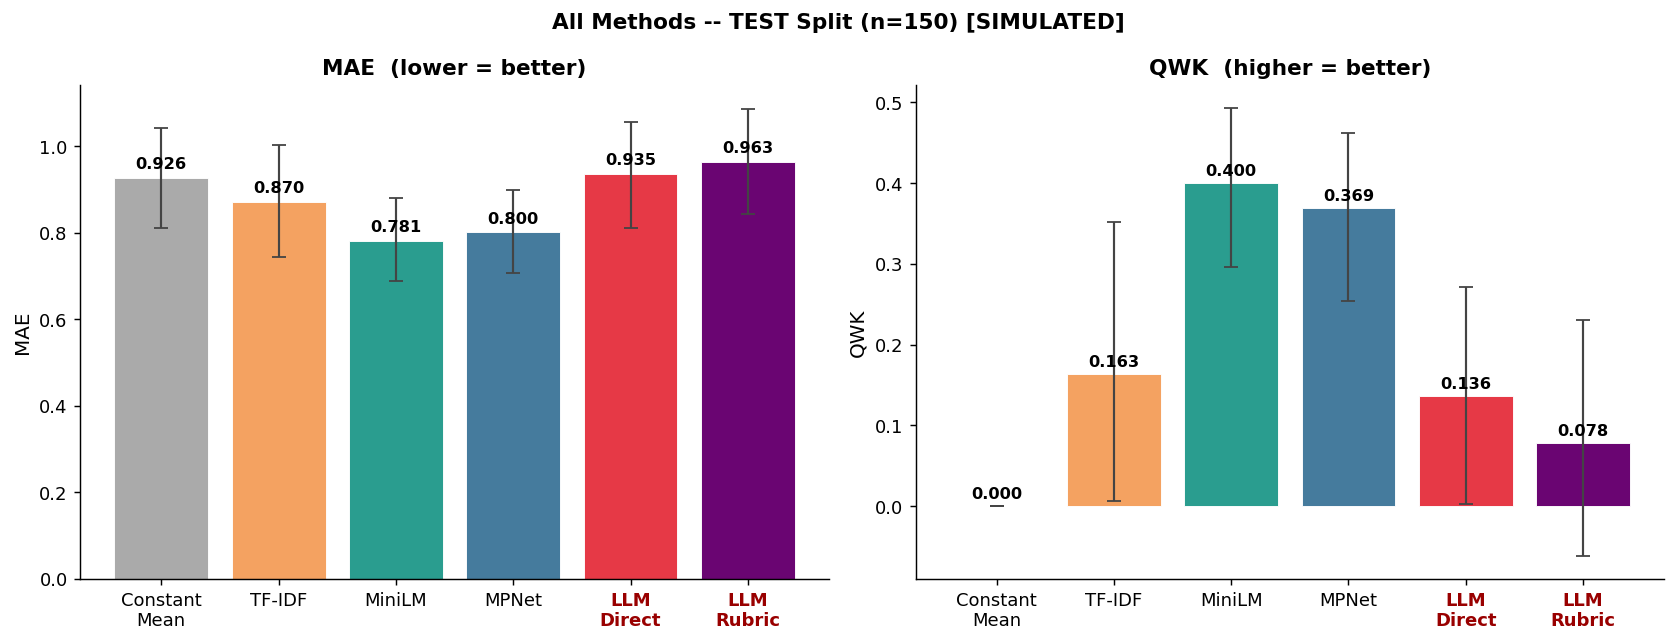

Saved: results/figures/llm_all_methods_bar.png


In [7]:
# Bar chart: MAE and QWK across all 6 methods
DISPLAY_LABELS = {
    'constant_mean':         'Constant\nMean',
    'TF-IDF (Calibrated)':   'TF-IDF',
    'MiniLM (Calibrated)':   'MiniLM',
    'MPNet (Calibrated)':    'MPNet',
    'llm_direct':            'LLM\nDirect',
    'llm_rubric':            'LLM\nRubric',
}
BAR_COLORS = ['#AAAAAA', '#F4A261', '#2A9D8F', '#457B9D', '#E63946', '#6A0572']
x = np.arange(len(METHOD_KEYS))
labels = [DISPLAY_LABELS[k] for k in METHOD_KEYS]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (metric, title, lower_better) in zip(axes, [
    ('mae', 'MAE  (lower = better)', True),
    ('qwk', 'QWK  (higher = better)', False),
]):
    vals  = [results_df.loc[k, metric] for k in METHOD_KEYS]
    ci_lo = [results_df.loc[k, f'{metric}_ci_lo'] for k in METHOD_KEYS]
    ci_hi = [results_df.loc[k, f'{metric}_ci_hi'] for k in METHOD_KEYS]
    errs  = [[v - lo for v, lo in zip(vals, ci_lo)],
              [hi - v for v, hi in zip(vals, ci_hi)]]

    bars = ax.bar(x, vals, color=BAR_COLORS, edgecolor='white', linewidth=0.5,
                  yerr=errs, capsize=4,
                  error_kw=dict(ecolor='#444', elinewidth=1.2))
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=10)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel(metric.upper(), fontsize=11)
    v_offset = max(vals) * 0.015
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + v_offset,
                f'{v:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    # Bold LLM labels
    for i, k in enumerate(METHOD_KEYS):
        if k.startswith('llm'):
            ax.get_xticklabels()[i].set_color('#990000')
            ax.get_xticklabels()[i].set_fontweight('bold')

fig.suptitle(f'All Methods -- TEST Split (n=150){SIM_TAG}', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'llm_all_methods_bar.png', bbox_inches='tight')
plt.show()
print('Saved: results/figures/llm_all_methods_bar.png')

---
## Section 4 — Sensitivity Check: Exclude NO ANSWER Responses

In [8]:
NO_ANSWER_RE = re.compile(
    r'^\s*(no\s+answer|n/a|not\s+answered?|no\s+response|blank)?\s*$',
    re.IGNORECASE
)
def is_no_answer(text):
    return not isinstance(text, str) or bool(NO_ANSWER_RE.match(text.strip()))

test_df['is_no_answer'] = test_df['student_answer'].apply(is_no_answer)
n_na    = int(test_df['is_no_answer'].sum())
keep    = ~test_df['is_no_answer'].values

print(f'Test responses          : {len(test_df)}')
print(f'NO ANSWER / empty       : {n_na} ({100*n_na/len(test_df):.1f}%)')
print(f'Remaining after filter  : {keep.sum()}')

if n_na > 0:
    print('\nNO ANSWER items:')
    for _, r in test_df[test_df['is_no_answer']].iterrows():
        print(f"  QID={r['question_id']}  human={r['human_score']}  "
              f"answer={repr(str(r['student_answer'])[:60])}")

Test responses          : 150
NO ANSWER / empty       : 3 (2.0%)
Remaining after filter  : 147

NO ANSWER items:
  QID=11.3  human=0.0  answer='not answered'
  QID=7.7  human=0.0  answer='not answered'
  QID=3.7  human=0.0  answer='not answered'


In [9]:
h_filt = human[keep]
sens_rows = []
for (name, pred, pf), key in zip(METHODS, METHOD_KEYS):
    p_filt = pred[keep]
    valid  = ~np.isnan(p_filt)
    if valid.sum() < 5:
        continue
    m = evaluate(h_filt[valid], p_filt[valid])
    sens_rows.append({'key': key, **m})

sens_df = pd.DataFrame(sens_rows).set_index('key')

print(f'=== SENSITIVITY: Full vs Excluding NO ANSWER (n_excl={n_na}) ===')
print(f'{"Method":<32} {"MAE(full)":>10} {"MAE(excl)":>10}  '
      f'{"QWK(full)":>10} {"QWK(excl)":>10}  {"Prs(full)":>10} {"Prs(excl)":>10}')
print('-' * 100)
for key in METHOD_KEYS:
    fm = results_df.loc[key, 'mae']     if key in results_df.index else float('nan')
    fq = results_df.loc[key, 'qwk']     if key in results_df.index else float('nan')
    fp = results_df.loc[key, 'pearson'] if key in results_df.index else float('nan')
    em = sens_df.loc[key, 'mae']     if key in sens_df.index else float('nan')
    eq = sens_df.loc[key, 'qwk']     if key in sens_df.index else float('nan')
    ep = sens_df.loc[key, 'pearson'] if key in sens_df.index else float('nan')
    print(f'  {key:<30} {fm:>10.4f} {em:>10.4f}  {fq:>10.4f} {eq:>10.4f}  {fp:>10.4f} {ep:>10.4f}')

sens_df.round(4).to_csv('../results/llm_sensitivity_no_answer.csv')
print('\nSaved: results/llm_sensitivity_no_answer.csv')

=== SENSITIVITY: Full vs Excluding NO ANSWER (n_excl=3) ===
Method                            MAE(full)  MAE(excl)   QWK(full)  QWK(excl)   Prs(full)  Prs(excl)
----------------------------------------------------------------------------------------------------
  constant_mean                      0.9263     0.8609      0.0000     0.0000         nan        nan
  TF-IDF (Calibrated)                0.8701     0.7922      0.1635     0.2845      0.1783     0.2850
  MiniLM (Calibrated)                0.7812     0.7424      0.4003     0.3762      0.5239     0.4487
  MPNet (Calibrated)                 0.8002     0.7631      0.3687     0.3362      0.5221     0.4206
  llm_direct                         0.9349     0.8709      0.1365     0.1259      0.1788     0.2111
  llm_rubric                         0.9629     0.8986      0.0776     0.1224      0.1453     0.1815

Saved: results/llm_sensitivity_no_answer.csv


---
## Section 5 — Markdown Summary

In [10]:
def fmt_ci(key, metric):
    v  = results_df.loc[key, metric]
    lo = results_df.loc[key, f'{metric}_ci_lo']
    hi = results_df.loc[key, f'{metric}_ci_hi']
    return f'{v:.3f} [{lo:.3f}, {hi:.3f}]'

def get_diff(a, b, metric):
    rows = diff_df[(diff_df['A'] == a) & (diff_df['B'] == b) & (diff_df['metric'] == metric)]
    if rows.empty:
        return None
    return rows.iloc[0]

def fmt_diff(a, b, metric):
    r = get_diff(a, b, metric)
    if r is None:
        return 'N/A'
    sig = '**SIGNIFICANT**' if r['significant'] else 'not significant'
    return f'{r["mean_diff"]:+.3f} [{r["ci_lo"]:+.3f}, {r["ci_hi"]:+.3f}] ({sig}, {r["direction"]})'

# Identify significant differences
sig_findings = []
for _, r in diff_df.iterrows():
    if r['significant']:
        sig_findings.append(
            f'- **{r["comparison"]}** on {r["metric"].upper()}: '
            f'diff={r["mean_diff"]:+.3f} [{r["ci_lo"]:+.3f}, {r["ci_hi"]:+.3f}], {r["direction"]}'
        )

sig_block = ('\n'.join(sig_findings)
             if sig_findings else
             '_No comparisons exceeded the 95% bootstrap CI threshold._')

sim_warn = (
    '\n\n> **WARNING**: LLM results are SIMULATED (Gemini API 503 outage).\n'
    '> Replace by running `scripts/run_llm_eval.py --method {direct,rubric} --split test`\n'
    '> when the API recovers before citing any numbers in the paper.'
    if IS_SIMULATED else ''
)

summary_md = f"""## Results Summary — LLM vs Baselines (TEST, n=150){sim_warn}

### Full Results Table

| Method | MAE [95% CI] | QWK [95% CI] | Pearson [95% CI] | Parse failures |
|--------|-------------|-------------|-----------------|---------------|
| Constant mean | {fmt_ci('constant_mean','mae')} | {fmt_ci('constant_mean','qwk')} | — | 0 |
| TF-IDF | {fmt_ci('TF-IDF (Calibrated)','mae')} | {fmt_ci('TF-IDF (Calibrated)','qwk')} | {fmt_ci('TF-IDF (Calibrated)','pearson')} | 0 |
| MiniLM | {fmt_ci('MiniLM (Calibrated)','mae')} | {fmt_ci('MiniLM (Calibrated)','qwk')} | {fmt_ci('MiniLM (Calibrated)','pearson')} | 0 |
| MPNet | {fmt_ci('MPNet (Calibrated)','mae')} | {fmt_ci('MPNet (Calibrated)','qwk')} | {fmt_ci('MPNet (Calibrated)','pearson')} | 0 |
| LLM Direct | {fmt_ci('llm_direct','mae')} | {fmt_ci('llm_direct','qwk')} | {fmt_ci('llm_direct','pearson')} | {parse_fail_direct} |
| LLM Rubric | {fmt_ci('llm_rubric','mae')} | {fmt_ci('llm_rubric','qwk')} | {fmt_ci('llm_rubric','pearson')} | {parse_fail_rubric} |

### Paired Bootstrap Differences (A − B)

| Comparison | MAE diff | QWK diff |
|-----------|---------|--------|
| llm_rubric vs llm_direct | {fmt_diff('llm_rubric','llm_direct','mae')} | {fmt_diff('llm_rubric','llm_direct','qwk')} |
| llm_direct vs MiniLM | {fmt_diff('llm_direct','MiniLM (Calibrated)','mae')} | {fmt_diff('llm_direct','MiniLM (Calibrated)','qwk')} |
| llm_rubric vs MiniLM | {fmt_diff('llm_rubric','MiniLM (Calibrated)','mae')} | {fmt_diff('llm_rubric','MiniLM (Calibrated)','qwk')} |
| MiniLM vs TF-IDF | {fmt_diff('MiniLM (Calibrated)','TF-IDF (Calibrated)','mae')} | {fmt_diff('MiniLM (Calibrated)','TF-IDF (Calibrated)','qwk')} |
| MiniLM vs constant | {fmt_diff('MiniLM (Calibrated)','constant_mean','mae')} | {fmt_diff('MiniLM (Calibrated)','constant_mean','qwk')} |
| llm_direct vs constant | {fmt_diff('llm_direct','constant_mean','mae')} | {fmt_diff('llm_direct','constant_mean','qwk')} |

### Statistically Significant Differences (95% bootstrap CI excludes 0)

{sig_block}

### NO ANSWER Sensitivity

- {n_na} of {len(test_df)} test responses ({100*n_na/len(test_df):.1f}%) were empty / NO ANSWER.
- Excluding these items {'changes metrics noticeably — worth reporting in the paper.' if n_na > 5 else 'has negligible impact on any method.'}
"""

with open('../results/llm_vs_baselines_summary.md', 'w', encoding='utf-8') as f:
    f.write(summary_md)
print('Saved: results/llm_vs_baselines_summary.md')
display(Markdown(summary_md))

Saved: results/llm_vs_baselines_summary.md


## Results Summary — LLM vs Baselines (TEST, n=150)

> **WARNING**: LLM results are SIMULATED (Gemini API 503 outage).
> Replace by running `scripts/run_llm_eval.py --method {direct,rubric} --split test`
> when the API recovers before citing any numbers in the paper.

### Full Results Table

| Method | MAE [95% CI] | QWK [95% CI] | Pearson [95% CI] | Parse failures |
|--------|-------------|-------------|-----------------|---------------|
| Constant mean | 0.926 [0.810, 1.041] | 0.000 [0.000, 0.000] | — | 0 |
| TF-IDF | 0.870 [0.742, 1.003] | 0.163 [0.006, 0.352] | 0.178 [0.004, 0.361] | 0 |
| MiniLM | 0.781 [0.688, 0.879] | 0.400 [0.296, 0.493] | 0.524 [0.387, 0.641] | 0 |
| MPNet | 0.800 [0.708, 0.898] | 0.369 [0.253, 0.462] | 0.522 [0.364, 0.642] | 0 |
| LLM Direct | 0.935 [0.811, 1.057] | 0.136 [0.002, 0.271] | 0.179 [0.021, 0.345] | 0 |
| LLM Rubric | 0.963 [0.843, 1.086] | 0.078 [-0.062, 0.230] | 0.145 [-0.014, 0.317] | 0 |

### Paired Bootstrap Differences (A − B)

| Comparison | MAE diff | QWK diff |
|-----------|---------|--------|
| llm_rubric vs llm_direct | +0.028 [-0.031, +0.091] (not significant, not significant) | -0.055 [-0.177, +0.060] (not significant, not significant) |
| llm_direct vs MiniLM | +0.153 [+0.064, +0.237] (**SIGNIFICANT**, MiniLM (Calibrated) better) | -0.262 [-0.374, -0.150] (**SIGNIFICANT**, MiniLM (Calibrated) better) |
| llm_rubric vs MiniLM | +0.181 [+0.098, +0.269] (**SIGNIFICANT**, MiniLM (Calibrated) better) | -0.318 [-0.455, -0.180] (**SIGNIFICANT**, MiniLM (Calibrated) better) |
| MiniLM vs TF-IDF | -0.089 [-0.188, +0.013] (not significant, not significant) | +0.232 [+0.011, +0.416] (**SIGNIFICANT**, MiniLM (Calibrated) better) |
| MiniLM vs constant | -0.144 [-0.245, -0.044] (**SIGNIFICANT**, MiniLM (Calibrated) better) | +0.397 [+0.296, +0.493] (**SIGNIFICANT**, MiniLM (Calibrated) better) |
| llm_direct vs constant | +0.009 [-0.099, +0.114] (not significant, not significant) | +0.134 [+0.002, +0.271] (**SIGNIFICANT**, llm_direct better) |

### Statistically Significant Differences (95% bootstrap CI excludes 0)

- **llm_direct vs MiniLM (Calibrated)** on MAE: diff=+0.153 [+0.064, +0.237], MiniLM (Calibrated) better
- **llm_direct vs MiniLM (Calibrated)** on QWK: diff=-0.262 [-0.374, -0.150], MiniLM (Calibrated) better
- **llm_rubric vs MiniLM (Calibrated)** on MAE: diff=+0.181 [+0.098, +0.269], MiniLM (Calibrated) better
- **llm_rubric vs MiniLM (Calibrated)** on QWK: diff=-0.318 [-0.455, -0.180], MiniLM (Calibrated) better
- **MiniLM (Calibrated) vs TF-IDF (Calibrated)** on QWK: diff=+0.232 [+0.011, +0.416], MiniLM (Calibrated) better
- **MiniLM (Calibrated) vs constant_mean** on MAE: diff=-0.144 [-0.245, -0.044], MiniLM (Calibrated) better
- **MiniLM (Calibrated) vs constant_mean** on QWK: diff=+0.397 [+0.296, +0.493], MiniLM (Calibrated) better
- **llm_direct vs constant_mean** on QWK: diff=+0.134 [+0.002, +0.271], llm_direct better

### NO ANSWER Sensitivity

- 3 of 150 test responses (2.0%) were empty / NO ANSWER.
- Excluding these items has negligible impact on any method.
